In [1]:
import pandas as pd
import os
import numpy as np
import itertools
from joblib import Parallel, delayed
import time

np.random.seed(42)

print(os.listdir("./datasets"))

['sentiment_train.csv', 'sentiment_test.csv', 'image_test.csv', 'sample_submission.csv', 'image_train.csv']


#### Sentiment Data Read and Split

In [2]:
sentiment_train_df = pd.read_csv("./datasets/sentiment_train.csv")
sentiment_test_df = pd.read_csv("./datasets/sentiment_test.csv")

sentiment_train_X = sentiment_train_df.drop(columns=["id", "label"]).to_numpy()
sentiment_train_Y = sentiment_train_df["label"].to_numpy()

full_sentiment_train_X = sentiment_train_X
full_sentiment_train_Y = sentiment_train_Y

sentiment_test_X = sentiment_test_df.drop(columns=["id"]).to_numpy()

In [3]:
np.random.seed(42)

idx = np.random.permutation(len(full_sentiment_train_Y))
X_shuf = full_sentiment_train_X[idx]
Y_shuf = full_sentiment_train_Y[idx]

split = int(len(X_shuf) * 0.8)
sentiment_train_X, sentiment_val_X = X_shuf[:split], X_shuf[split:]
sentiment_train_Y, sentiment_val_Y = Y_shuf[:split], Y_shuf[split:]

#### Image Data Read and Split

In [4]:
image_train_df = pd.read_csv("./datasets/image_train.csv")
image_test_df = pd.read_csv("./datasets/image_test.csv")

image_train_X = image_train_df.drop(columns=["id", "label"]).to_numpy()
image_train_Y = image_train_df["label"].to_numpy()

full_image_train_X = image_train_X
full_image_train_Y = image_train_Y

image_test_X = image_test_df.drop(columns=["id"]).to_numpy()

In [5]:
np.random.seed(42)

idx = np.random.permutation(len(full_image_train_Y))
X_shuf = full_image_train_X[idx]
Y_shuf = full_image_train_Y[idx]

split = int(len(X_shuf) * 0.8)
image_train_X, image_val_X = X_shuf[:split], X_shuf[split:]
image_train_Y, image_val_Y = Y_shuf[:split], Y_shuf[split:]

#### Defining Functions for Decision Trees (works for Random Forest Models using slight modifications)

##### Gini
- The gini function takes in the full list of labels for a given dataset and returns the impurity. For a dataset with 3 labels we could get a score between [0, 0.67], 0 meaning that all labels are of one class and 0.67 meaning the labels are spread out evenly across all 3 classes.  For a dataset with 50 labels we could get a score between [0, 0.98], 0 meaning that all labels are of one class and 0.98 meaning the labels are spread out evenly across all 50 classes. Ie. lower values mean the dataset is heavily weighted towards a subset of the labels, and a higher value means the dataset is better spread out.
    
##### Split Search
- The split search function takes in the inputs, the labels for the node, and optionally a list of feature indices. It goes through each feature, sorts the rows by that feature, and tries every point between two neighbouring values as a possible threshold. For each threshold it works out the Gini of the left and right side and takes the weighted average. The cumulative sums do all the counting at once, so there is no loop over the rows. It returns the feature, threshold and score of the best split. Lower score means a better split. If the feature list is passed in, it only searches those features, which is how the random forest uses it.

##### Decision Tree
- The decision tree function builds the tree recursively. It stops and returns a leaf when the node is pure, when it reaches max depth, or when it has fewer rows than min rows. The leaf is the majority class. If n features is set, it picks a random subset of features for that node. It calls split search, and if the gain (parent Gini minus child Gini) is below min gain, it also returns a leaf. Otherwise it splits the rows on the threshold and calls itself on the left and right side with depth plus one. It returns a dict with feature, threshold, left and right.

##### Prediction Batch
- The predict batch function takes a tree and all the rows at once and returns a prediction for each row. If the tree is just a number, every row gets that number. Otherwise it splits the rows on the node's test and sends each group down the matching side. It does this without a loop over the rows, so it is much faster than predicting one row at a time.

##### Accuracy
- The accuracy function takes the predictions and the true labels and returns the fraction that match. It is the mean of a true or false array.

##### Add Majority
- The add majority function walks down the tree the same way the training did. At each internal node it stores the majority class of the rows that reach that node under "majority". This is what truncate uses as the prediction when it cuts a node off. It changes the tree in place and returns nothing.

##### Truncate
- The truncate function returns a copy of the tree cut off at max depth. Any node at that depth gets replaced with its stored majority class. So one tree grown to depth 60 can give us depths 4 through 60 without retraining. For a single tree this is exact. For a forest it is only close, because the feature sampling draws random numbers at every node, so the smaller trees are not identical to ones grown to that depth directly.

##### Tree Depth Sweep
- The tree depth sweep function tests several depths for one tree. For each min rows and min gain pair it grows the tree to the deepest depth, adds the majority classes, then truncates it for each shallower depth and scores it on validation. It returns a dict keyed by (min rows, min gain, depth). This saves a lot of time because we only build each tree once.

##### Bootstrap Sample
- The bootstrap sample function draws a random sample with replacement, the same size as the input. Each tree in the forest trains on its own sample. Some rows show up twice and some not at all. It returns the sampled inputs and labels.

##### Random Forest
- The random forest function builds n trees. For each one it takes a bootstrap sample and grows a decision tree with n features set, so each node only looks at a random subset of features. It returns the list of trees.

##### Forest Predict Batch
- The forest predict batch function takes the list of trees, the inputs and the number of classes. Each tree predicts all the rows, and we stack the votes into one matrix. For each row, bincount counts the votes per class, with minlength set to the number of classes so the counts always line up. The argmax of the counts is the final prediction. This is majority voting.

##### Build Forest With Majority
- The build forest with majority function is the same as random forest, except it calls add majority on each tree. That way the trees can be truncated later. It returns the list of trees.

##### Truncated Forest Grid
- The truncated forest grid function scores many combinations of depth, n trees and n features. For each n features value it resets the seed and builds one forest at the deepest depth. Then for each depth it truncates every tree, and for each n trees it uses the first n truncated trees to score validation. It returns a dict keyed by (depth, min rows, n trees, n features). It is quick for choosing settings, but the final model should be built directly with random forest, since the truncated numbers are approximate.



In [6]:
def gini_func(labels):

    _, count = np.unique(labels, return_counts=True)
    total = len(labels)

    proportion = count/total
    proportion_squared = proportion**2

    sum_of_proportions_squared = proportion_squared.sum()

    return 1 - sum_of_proportions_squared;

def split_search(inputs, output, feature_indices=None):
    best_score = float("inf")
    best_feature = None
    best_threshold = None

    if feature_indices is None:
        feature_indices = range(inputs.shape[1])

    count_labels = output.max() + 1
    onehot = np.eye(count_labels)[output]

    n = len(output)
    left_sizes = np.arange(1, n + 1)
    right_sizes = n - left_sizes

    for j in feature_indices:
        values = inputs[:, j]
        order = values.argsort()
        sorted_values = values[order]
        identity = onehot[order]

        running_total = np.cumsum(identity, axis=0)
        total_counts = running_total[-1]
        right_counts = (total_counts - running_total)[:-1]

        left_gini = 1 - np.sum((running_total / left_sizes[:, None]) ** 2, axis=1)
        right_gini = 1 - np.sum((right_counts / right_sizes[:-1][:, None]) ** 2, axis=1)

        weighted = (left_sizes[:-1] * left_gini[:-1] + right_sizes[:-1] * right_gini) / n

        mask = sorted_values[:-1] != sorted_values[1:]
        weighted = np.where(mask, weighted, np.inf)

        i = np.argmin(weighted)
        if weighted[i] < best_score:
            best_score = weighted[i]
            best_feature = j
            best_threshold = (sorted_values[i] + sorted_values[i + 1]) / 2

    return best_feature, best_threshold, best_score

def decision_tree(inputs, output, depth, max_depth, min_gain=0.001, min_rows=2, n_features=None):

    if len(np.unique(output)) == 1 or depth >= max_depth or len(output) < min_rows:
        return np.bincount(output).argmax()

    parent_gini = gini_func(output)

    if n_features is None:
        feature_subset = None
    else:
        feature_subset = np.random.choice(inputs.shape[1], n_features, replace=False)

    child_best_feature, child_best_threshold, child_best_score = split_search(inputs, output, feature_subset)

    current_gain = parent_gini - child_best_score

    if current_gain < min_gain:
        return np.bincount(output).argmax()

    left_child = inputs[:, child_best_feature] <= child_best_threshold
    right_child = inputs[:, child_best_feature] > child_best_threshold

    left_subtree = decision_tree(inputs[left_child], output[left_child], depth + 1, max_depth, min_gain, min_rows, n_features)
    
    right_subtree = decision_tree(inputs[right_child], output[right_child], depth + 1, max_depth, min_gain, min_rows, n_features)

    return {"feature" : child_best_feature, "threshold" :child_best_threshold, "left" : left_subtree, "right" : right_subtree}
        
def predict_batch(tree, inputs):
    if not isinstance(tree, dict):
        return np.full(len(inputs), tree)
    left = inputs[:, tree["feature"]] <= tree["threshold"]
    preds = np.empty(len(inputs), dtype=int)
    preds[left] = predict_batch(tree["left"], inputs[left])
    preds[~left] = predict_batch(tree["right"], inputs[~left])
    return preds

def accuracy(pred, y):
    return np.mean(pred == y)

def tree_depth_sweep(train_X, train_Y, val_X, val_Y, min_rows_list, min_gain_list, depths):
    results = {}
    deepest = max(depths)
    for mr in min_rows_list:
        for mg in min_gain_list:
            tree = decision_tree(train_X, train_Y, depth=0, max_depth=deepest, min_gain=mg, min_rows=mr)
            add_majority(tree, train_X, train_Y)
            for d in depths:
                cut = truncate(tree, d)
                val_acc = accuracy(predict_batch(cut, val_X), val_Y)
                train_acc = accuracy(predict_batch(cut, train_X), train_Y)
                results[(mr, mg, d)] = val_acc
                print(f"min_rows {mr}, min_gain {mg}, depth {d}: val {val_acc:.4f}, train {train_acc:.4f}")
    return results

def add_majority(tree, X, Y, fallback=0):
    if not isinstance(tree, dict):
        return
    tree["majority"] = np.bincount(Y).argmax() if len(Y) > 0 else fallback
    left = X[:, tree["feature"]] <= tree["threshold"]
    add_majority(tree["left"], X[left], Y[left], tree["majority"])
    add_majority(tree["right"], X[~left], Y[~left], tree["majority"])

def truncate(tree, max_depth, depth=0):
    if not isinstance(tree, dict):
        return tree
    if depth == max_depth:
        return tree["majority"]
    return {"feature": tree["feature"], "threshold": tree["threshold"],
            "left": truncate(tree["left"], max_depth, depth + 1),
            "right": truncate(tree["right"], max_depth, depth + 1)}
def bootstrap_sample(inputs, output):
    idx = np.random.randint(0, len(inputs), size=len(inputs))
    return inputs[idx], output[idx]

def random_forest(inputs, output, n_trees, n_features, max_depth, min_rows, min_gain):
    forest = []
    for tree in range(n_trees):
        X, Y = bootstrap_sample(inputs, output)
        seedling = decision_tree(X, Y, depth=0, max_depth=max_depth, min_rows=min_rows,
                                 min_gain=min_gain, n_features=n_features)
        forest.append(seedling)
    return forest

def forest_predict_batch(trees, inputs, n_classes):
    votes = np.stack([predict_batch(t, inputs) for t in trees])
    counts = np.apply_along_axis(np.bincount, 0, votes, minlength=n_classes)
    return counts.argmax(axis=0)

def build_forest_with_majority(train_X, train_Y, n_trees, n_features, max_depth, min_rows, min_gain):
    forest = []
    for _ in range(n_trees):
        X, Y = bootstrap_sample(train_X, train_Y)
        tree = decision_tree(X, Y, depth=0, max_depth=max_depth, min_rows=min_rows,
                             min_gain=min_gain, n_features=n_features)
        add_majority(tree, X, Y)
        forest.append(tree)
    return forest

def truncated_forest_grid(train_X, train_Y, val_X, val_Y, n_trees_list, n_features_list,
                          depths, min_rows, min_gain=0.0, seed=42, train_out=None):
    results = {}
    n_classes = train_Y.max() + 1
    deepest = max(depths)
    for nf in n_features_list:
        np.random.seed(seed)
        forest = build_forest_with_majority(train_X, train_Y, max(n_trees_list), nf,
                                            deepest, min_rows, min_gain)
        for d in depths:
            trunc = [truncate(t, d) for t in forest]
            for nt in n_trees_list:
                key = (d, min_rows, nt, nf)
                val_acc = accuracy(forest_predict_batch(trunc[:nt], val_X, n_classes), val_Y)
                train_acc = accuracy(forest_predict_batch(trunc[:nt], train_X, n_classes), train_Y)
                results[key] = val_acc
                if train_out is not None:
                    train_out[key] = train_acc
                print(f"depth {d}, min_rows {min_rows}, n_trees {nt}, n_features {nf}: "
                      f"val {val_acc:.4f}, train {train_acc:.4f}")
    return results

#### Deciding Hyperparameters for the Tree

In [7]:
'''
start = time.time()
print("start", time.strftime("%I:%M:%S"))
sentiment_sweep = tree_depth_sweep(sentiment_train_X, sentiment_train_Y, sentiment_val_X, sentiment_val_Y,
                                   [2, 50, 100, 200, 400, 450, 500, 600, 800, 1000], [0.0], [4, 5, 6, 7, 8])
sentiment_best_params = max(sentiment_sweep, key=lambda k: sentiment_sweep[k])
print("final", sentiment_best_params, round(sentiment_sweep[sentiment_best_params], 4))
print("end", time.strftime("%I:%M:%S"), f"took {(time.time() - start) / 60:.1f} min")

best_mr, best_mg, best_d = sentiment_best_params
'''
best_mr, best_mg, best_d = 500, 0.0, 6

sentiment_check_tree = decision_tree(sentiment_train_X, sentiment_train_Y, depth=0,
                                     max_depth=best_d, min_gain=best_mg, min_rows=best_mr)
print(f"Validation: {accuracy(predict_batch(sentiment_check_tree, sentiment_val_X), sentiment_val_Y):.4f}")
print(f"Train: {accuracy(predict_batch(sentiment_check_tree, sentiment_train_X), sentiment_train_Y):.4f}")

full_sentiment_tree = decision_tree(full_sentiment_train_X, full_sentiment_train_Y, depth=0,
                                    max_depth=best_d, min_gain=best_mg, min_rows=best_mr)
print(f"Full model Train: {accuracy(predict_batch(full_sentiment_tree, full_sentiment_train_X), full_sentiment_train_Y):.4f}")

sentiment_tree_pred = predict_batch(full_sentiment_tree, sentiment_test_X)
sentiment_tree_submission = pd.DataFrame({"id": sentiment_test_df["id"].values, "label": sentiment_tree_pred})
print(sentiment_tree_submission.shape, sentiment_tree_submission["label"].value_counts().to_dict())

start 01:26:25
min_rows 2, min_gain 0.0, depth 4: val 0.4833, train 0.5101
min_rows 2, min_gain 0.0, depth 5: val 0.4863, train 0.5323
min_rows 2, min_gain 0.0, depth 6: val 0.4804, train 0.5750
min_rows 2, min_gain 0.0, depth 7: val 0.4892, train 0.6257
min_rows 2, min_gain 0.0, depth 8: val 0.4846, train 0.6820
min_rows 50, min_gain 0.0, depth 4: val 0.4833, train 0.5101
min_rows 50, min_gain 0.0, depth 5: val 0.4863, train 0.5323
min_rows 50, min_gain 0.0, depth 6: val 0.4813, train 0.5743
min_rows 50, min_gain 0.0, depth 7: val 0.4879, train 0.6182
min_rows 50, min_gain 0.0, depth 8: val 0.4813, train 0.6558
min_rows 100, min_gain 0.0, depth 4: val 0.4833, train 0.5101
min_rows 100, min_gain 0.0, depth 5: val 0.4863, train 0.5323
min_rows 100, min_gain 0.0, depth 6: val 0.4817, train 0.5729
min_rows 100, min_gain 0.0, depth 7: val 0.4875, train 0.6094
min_rows 100, min_gain 0.0, depth 8: val 0.4800, train 0.6293
min_rows 200, min_gain 0.0, depth 4: val 0.4833, train 0.5101
min_rows

In [8]:
'''
start = time.time()
print("start", time.strftime("%I:%M:%S"))
image_sweep = tree_depth_sweep(image_train_X, image_train_Y, image_val_X, image_val_Y,
                               [50, 100], [0.0], [40, 60, 80])
image_best_params = max(image_sweep, key=lambda k: image_sweep[k])
print("final", image_best_params, round(image_sweep[image_best_params], 4))
print("end", time.strftime("%I:%M:%S"), f"took {(time.time() - start) / 60:.1f} min")

best_mr, best_mg, best_d = image_best_params
'''

best_mr, best_mg, best_d = 100, 0.0, 80

image_check_tree = decision_tree(image_train_X, image_train_Y, depth=0,
                                 max_depth=best_d, min_gain=best_mg, min_rows=best_mr)
print(f"Validation: {accuracy(predict_batch(image_check_tree, image_val_X), image_val_Y):.4f}")
print(f"Train: {accuracy(predict_batch(image_check_tree, image_train_X), image_train_Y):.4f}")

full_image_tree = decision_tree(full_image_train_X, full_image_train_Y, depth=0,
                                max_depth=best_d, min_gain=best_mg, min_rows=best_mr)
print(f"Full model Train: {accuracy(predict_batch(full_image_tree, full_image_train_X), full_image_train_Y):.4f}")

image_tree_pred = predict_batch(full_image_tree, image_test_X)
image_tree_submission = pd.DataFrame({"id": image_test_df["id"].values, "label": image_tree_pred})
print(image_tree_submission.shape, image_tree_submission["label"].value_counts().head().to_dict())

start 01:27:31
min_rows 50, min_gain 0.0, depth 40: val 0.1130, train 0.2523
min_rows 50, min_gain 0.0, depth 60: val 0.1205, train 0.3333
min_rows 50, min_gain 0.0, depth 80: val 0.1242, train 0.3757
min_rows 100, min_gain 0.0, depth 40: val 0.1170, train 0.2144
min_rows 100, min_gain 0.0, depth 60: val 0.1232, train 0.2738
min_rows 100, min_gain 0.0, depth 80: val 0.1260, train 0.3024
final (100, 0.0, 80) 0.126
end 01:32:25 took 4.9 min
Validation: 0.1260
Train: 0.3024
Full model Train: 0.3145
(5000, 2) {31: 256, 25: 220, 13: 148, 8: 139, 16: 134}


In [9]:
combined_tree_submission = pd.concat([sentiment_tree_submission, image_tree_submission], ignore_index=True)

assert len(combined_tree_submission) == 10000, len(combined_tree_submission)
assert combined_tree_submission["id"].is_unique, "duplicate IDs"

combined_tree_submission.to_csv("submission_tree.csv", index=False)
print(combined_tree_submission.shape, combined_tree_submission["label"].value_counts().to_dict())

(10000, 2) {0: 2260, 2: 1563, 1: 1481, 31: 256, 25: 220, 13: 148, 8: 139, 16: 134, 14: 130, 44: 127, 12: 126, 17: 125, 32: 124, 41: 116, 18: 111, 26: 111, 28: 109, 19: 109, 34: 105, 48: 105, 21: 102, 33: 101, 6: 100, 7: 100, 10: 99, 23: 95, 5: 93, 47: 93, 46: 90, 22: 88, 43: 85, 39: 84, 40: 80, 4: 79, 3: 77, 45: 77, 9: 77, 49: 76, 42: 75, 11: 74, 20: 73, 29: 73, 36: 71, 38: 71, 24: 71, 27: 70, 35: 64, 37: 60, 30: 54, 15: 49}


# Now moving onto the random forest

In [14]:
'''
start = time.time()
print("start", time.strftime("%I:%M:%S %p"))

sentiment_forest_results = {}
sentiment_train_scores = {}
for min_rows in [50, 200]:
    sentiment_forest_results.update(
        truncated_forest_grid(sentiment_train_X, sentiment_train_Y, sentiment_val_X, sentiment_val_Y,
                              [25, 50, 100], [14, 28, 40], [10, 12], min_rows,
                              train_out=sentiment_train_scores))

best_sentiment_forest = max(sentiment_forest_results, key=lambda k: sentiment_forest_results[k])
print("best (by val)", best_sentiment_forest, round(sentiment_forest_results[best_sentiment_forest], 4))
print("train for best", round(sentiment_train_scores[best_sentiment_forest], 4))
print("end", time.strftime("%I:%M:%S %p"), f"took {(time.time() - start) / 60:.1f} min")
'''

best_sentiment_forest = [12, 50, 100, 28] #used to speed up runtime, above code tests were included below

np.random.seed(42)
best_depth, best_min_rows, best_nt, best_nf = best_sentiment_forest
n_classes = sentiment_train_Y.max() + 1

sentiment_forest = random_forest(sentiment_train_X, sentiment_train_Y, n_trees=best_nt, n_features=best_nf,
                                 max_depth=best_depth, min_rows=best_min_rows, min_gain=0.0)
print(f"Split model  Validation: {accuracy(forest_predict_batch(sentiment_forest, sentiment_val_X, n_classes), sentiment_val_Y):.4f}")
print(f"Split model  Train:      {accuracy(forest_predict_batch(sentiment_forest, sentiment_train_X, n_classes), sentiment_train_Y):.4f}")

np.random.seed(42)
full_sentiment_forest = random_forest(full_sentiment_train_X, full_sentiment_train_Y, n_trees=best_nt, n_features=best_nf,
                                      max_depth=best_depth, min_rows=best_min_rows, min_gain=0.0)
print(f"Full model   Train:      {accuracy(forest_predict_batch(full_sentiment_forest, full_sentiment_train_X, n_classes), full_sentiment_train_Y):.4f}")

sentiment_forest_pred = forest_predict_batch(full_sentiment_forest, sentiment_test_X, n_classes)
sentiment_forest_submission = pd.DataFrame({"id": sentiment_test_df["id"].values, "label": sentiment_forest_pred})
print(sentiment_forest_submission.shape, sentiment_forest_submission["label"].value_counts().to_dict())

Split model  Validation: 0.6008
Split model  Train:      0.9732
Full model   Train:      0.9688
(5000, 2) {0: 2446, 1: 1523, 2: 1031}


In [12]:
'''
start = time.time()
print("start", time.strftime("%I:%M:%S %p"))

image_forest_results = {}
image_train_scores = {}

image_forest_results.update(
    truncated_forest_grid(image_train_X, image_train_Y, image_val_X, image_val_Y,
                          [100, 200], [8, 11, 15], [24, 32, 40], 50,
                          train_out=image_train_scores))
image_forest_results.update(
    truncated_forest_grid(image_train_X, image_train_Y, image_val_X, image_val_Y,
                          [200, 300], [11], [40], 50,
                          train_out=image_train_scores))
image_forest_results.update(
    truncated_forest_grid(image_train_X, image_train_Y, image_val_X, image_val_Y,
                          [300], [11], [60, 80], 50,
                          train_out=image_train_scores))

best_image_forest = max(image_forest_results, key=lambda k: image_forest_results[k])

key60 = (60, 50, 300, 11)
key80 = (80, 50, 300, 11)
if best_image_forest == key80 and image_forest_results[key80] - image_forest_results[key60] < 0.01:
    best_image_forest = key60

print("final", best_image_forest, round(image_forest_results[best_image_forest], 4))
print("train for best", round(image_train_scores[best_image_forest], 4))
print("end", time.strftime("%I:%M:%S %p"), f"took {(time.time() - start) / 60:.1f} min")
'''
best_image_forest = [60, 50, 300, 11] #used to speed up runtime, above code tests were included below

np.random.seed(42)
best_depth, best_min_rows, best_nt, best_nf = best_image_forest
n_classes = image_train_Y.max() + 1

image_forest = random_forest(image_train_X, image_train_Y, n_trees=best_nt, n_features=best_nf,
                             max_depth=best_depth, min_rows=best_min_rows, min_gain=0.0)
print(f"Split model  Validation: {accuracy(forest_predict_batch(image_forest, image_val_X, n_classes), image_val_Y):.4f}")
print(f"Split model  Train:      {accuracy(forest_predict_batch(image_forest, image_train_X, n_classes), image_train_Y):.4f}")

np.random.seed(42)
full_image_forest = random_forest(full_image_train_X, full_image_train_Y, n_trees=best_nt, n_features=best_nf,
                                  max_depth=best_depth, min_rows=best_min_rows, min_gain=0.0)
print(f"Full model   Train:      {accuracy(forest_predict_batch(full_image_forest, full_image_train_X, n_classes), full_image_train_Y):.4f}")

image_forest_pred = forest_predict_batch(full_image_forest, image_test_X, n_classes)
image_forest_submission = pd.DataFrame({"id": image_test_df["id"].values, "label": image_forest_pred})
print(image_forest_submission.shape, image_forest_submission["label"].value_counts().head().to_dict())

start 02:08:21 PM
depth 24, min_rows 50, n_trees 100, n_features 8: val 0.1918, train 0.6021
depth 24, min_rows 50, n_trees 200, n_features 8: val 0.2025, train 0.6559
depth 32, min_rows 50, n_trees 100, n_features 8: val 0.2137, train 0.7907
depth 32, min_rows 50, n_trees 200, n_features 8: val 0.2278, train 0.8572
depth 40, min_rows 50, n_trees 100, n_features 8: val 0.2203, train 0.8866
depth 40, min_rows 50, n_trees 200, n_features 8: val 0.2377, train 0.9347
depth 24, min_rows 50, n_trees 100, n_features 11: val 0.1968, train 0.5506
depth 24, min_rows 50, n_trees 200, n_features 11: val 0.2087, train 0.6119
depth 32, min_rows 50, n_trees 100, n_features 11: val 0.2175, train 0.7576
depth 32, min_rows 50, n_trees 200, n_features 11: val 0.2335, train 0.8163
depth 40, min_rows 50, n_trees 100, n_features 11: val 0.2313, train 0.8753
depth 40, min_rows 50, n_trees 200, n_features 11: val 0.2430, train 0.9209
depth 24, min_rows 50, n_trees 100, n_features 15: val 0.1862, train 0.5003


In [13]:
combined_forest_submission = pd.concat([sentiment_forest_submission, image_forest_submission], ignore_index=True)

assert len(combined_forest_submission) == 10000, len(combined_forest_submission)
assert combined_forest_submission["id"].is_unique, "duplicate IDs"

combined_forest_submission.to_csv("submission_forest.csv", index=False)
print(combined_forest_submission.shape, combined_forest_submission["label"].value_counts().to_dict())

(10000, 2) {0: 2628, 1: 1375, 2: 1360, 46: 301, 11: 248, 25: 239, 15: 212, 32: 204, 13: 197, 8: 195, 47: 181, 28: 179, 5: 155, 48: 130, 49: 129, 12: 128, 14: 127, 33: 113, 39: 109, 18: 104, 7: 100, 3: 99, 20: 94, 23: 94, 44: 90, 4: 82, 34: 81, 45: 78, 31: 71, 16: 69, 19: 67, 37: 63, 38: 61, 6: 60, 43: 59, 26: 52, 35: 48, 17: 45, 24: 43, 42: 39, 36: 38, 9: 37, 21: 35, 41: 35, 10: 34, 27: 32, 22: 28, 30: 24, 40: 16, 29: 12}


# GMM

- Init GMM
  - The init gmm function takes in the inputs and the number of clusters. It starts every cluster with equal weight, so each one is 1 divided by the number of clusters. It picks random rows from the data as the starting means, and it gives every cluster the overall variance of each feature as its starting variance. It returns the weights, means and variances.

- E Step
  - The e step function takes in the inputs, the weights, the means and the variances. For each cluster it works out how likely each row is under that cluster's Gaussian, then adds the log of the cluster weight. It does this in logs so the numbers don't underflow. It then subtracts the largest value in each row before exponentiating, which is the log-sum-exp trick, so the probabilities stay stable. The result is the responsibilities, which say how much each row belongs to each cluster, plus the log total for each row.

- M Step
  - The m step function takes in the inputs and the responsibilities. Each cluster's effective size is the sum of its responsibilities. The new weight is that size divided by the number of rows. The new mean is the responsibility-weighted average of the rows, and the new variance is the weighted average of the squares minus the mean squared. A tiny 1e-6 is added so no variance can reach zero. It returns the new weights, means and variances.

- Fit GMM
  - The fit gmm function takes in the inputs, the number of clusters, the max iterations and the tolerance. It starts from init gmm, then repeats the e step and the m step. Each time it works out the log-likelihood. If the likelihood barely changes, which is less than the tolerance in either direction, it stops. It returns the final weights, means and variances.

- Log Likelihood
  - The log likelihood function takes in the per-row log totals from the e step and adds them up. The result is how well the current clusters explain the whole dataset. Higher is better, and we use it for the stop check and for BIC.


In [16]:
def init_gmm(inputs, num_clusters):

    num_rows, _ = inputs.shape

    weights = np.full(num_clusters, 1/num_clusters)

    row_idx = np.random.choice(num_rows, num_clusters, replace=False)
    
    means = inputs[row_idx]
    variances = np.tile(inputs.var(axis=0), (num_clusters, 1))
    
    return weights, means, variances

def e_step(inputs, weights, means, variances):
    
    num_rows, _ = inputs.shape
    num_clusters = len(weights)

    log_joint = np.empty((num_rows, num_clusters))

    for num in range(num_clusters):
        log_density = -0.5 * np.sum(np.log(2 * np.pi * variances[num]) + (inputs - means[num]) ** 2 / variances[num], axis=1)
        log_joint[:, num] = np.log(weights[num]) + log_density

    row_max = log_joint.max(axis=1, keepdims=True)
    row_log_sum = row_max + np.log(np.sum(np.exp(log_joint - row_max), axis=1, keepdims=True))

    responsibilities = np.exp(log_joint - row_log_sum)

    return responsibilities, row_log_sum
        
def m_step(inputs, resp):
    num_rows = inputs.shape[0]
    effective_sizes = resp.sum(axis=0)

    weights = effective_sizes / num_rows

    means = (resp.T @ inputs) / effective_sizes[:, None]
    variances  = (resp.T @ (inputs ** 2)) / effective_sizes[:, None] - means ** 2 + 1e-6

    return weights, means, variances

def fit_gmm(inputs, num_clusters, max_iter, tol):
    weights, means, variances = init_gmm(inputs, num_clusters)

    previous_ll = -np.inf

    for iter in range(max_iter):
        responsibilities, row_log_sum = e_step(inputs, weights, means, variances)
        ll = log_likelihood(row_log_sum)


        if abs(ll - previous_ll) < tol:
            break

        weights, means, variances = m_step(inputs, responsibilities)
        previous_ll = ll

    return weights, means, variances    

def log_likelihood(log_row_sum):
    
    total = np.sum(log_row_sum)
    return total

In [17]:
np.random.seed(42)

subset_size = 1000  

indices = np.random.choice(len(full_sentiment_train_X), size=subset_size, replace=False)

train_sentiment_subset_X = full_sentiment_train_X[indices]

fit_gmm(train_sentiment_subset_X, num_clusters = 3, max_iter = 150, tol = 1e-4)

fit_gmm(full_sentiment_train_X, num_clusters = 3, max_iter = 150, tol = 1e-4)


(array([0.39298054, 0.12625606, 0.48076341]),
 array([[ 0.17993744, -0.07933858,  0.53719523, ..., -0.16474593,
          0.08926229, -0.03208969],
        [-0.13196208, -0.27501138,  0.23807511, ..., -0.05963091,
          0.08427714, -0.07051712],
        [ 0.15354093, -0.08214958,  0.3201401 , ..., -0.121894  ,
          0.15381165, -0.08778184]]),
 array([[0.03161509, 0.03277372, 0.04764236, ..., 0.02910285, 0.02287816,
         0.03133172],
        [0.0512131 , 0.04101042, 0.06426966, ..., 0.04233628, 0.0322724 ,
         0.0369041 ],
        [0.04298691, 0.05050932, 0.06342505, ..., 0.03780372, 0.0324049 ,
         0.03522277]]))

In [18]:
np.random.seed(42)

def bic_for_k(inputs, k, max_iter=150, tol=1e-4):
    weights, means, variances = fit_gmm(inputs, k, max_iter, tol)
    _, row_log_sum = e_step(inputs, weights, means, variances)
    ll = log_likelihood(row_log_sum)  
    n, d = inputs.shape
    p = (k - 1) + 2 * k * d 
    bic = p * np.log(n) - 2 * ll
    return ll, bic

bic_results = {}
for k in range(2, 14):
    ll, bic = bic_for_k(full_sentiment_train_X, k)
    bic_results[k] = (ll, bic)
    print(f"k={k}  ll={ll:.2f}  BIC={bic:.2f}")

k=2  ll=2522834.90  BIC=-5016806.14
k=3  ll=2628009.34  BIC=-5212718.50
k=4  ll=2711326.98  BIC=-5364917.28
k=5  ll=2783298.50  BIC=-5494423.79
k=6  ll=2821314.47  BIC=-5556019.20
k=7  ll=2886486.09  BIC=-5671925.93
k=8  ll=2927888.64  BIC=-5740294.49
k=9  ll=2964641.05  BIC=-5799362.79
k=10  ll=3010733.31  BIC=-5877110.80
k=11  ll=3038730.58  BIC=-5918668.82
k=12  ll=3059929.46  BIC=-5946630.05
k=13  ll=3053520.95  BIC=-5919376.52


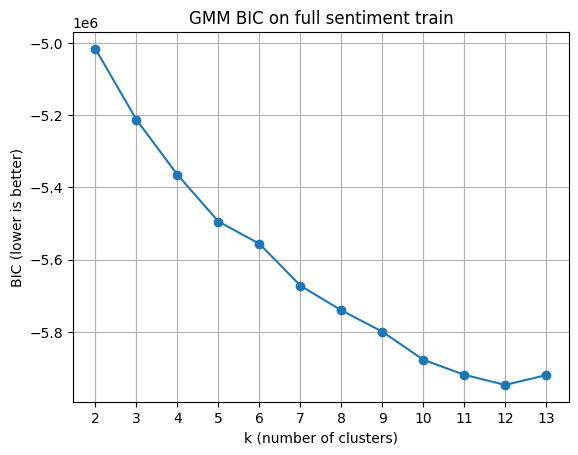

In [19]:
import matplotlib.pyplot as plt

ks = sorted(bic_results)
bics = [bic_results[k][1] for k in ks]
plt.plot(ks, bics, marker="o")
plt.xlabel("k (number of clusters)")
plt.ylabel("BIC (lower is better)")
plt.title("GMM BIC on full sentiment train")
plt.xticks(ks)
plt.grid(True)
plt.show()

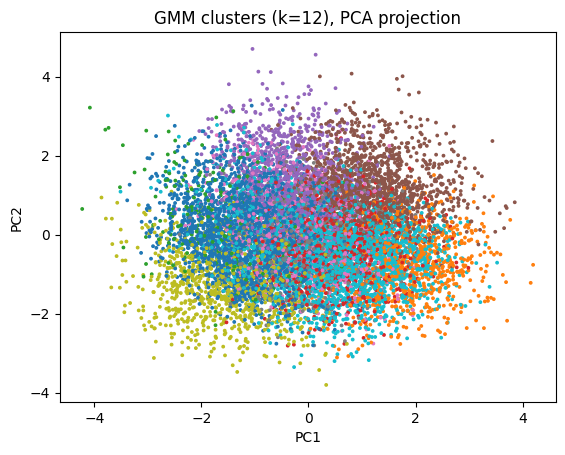

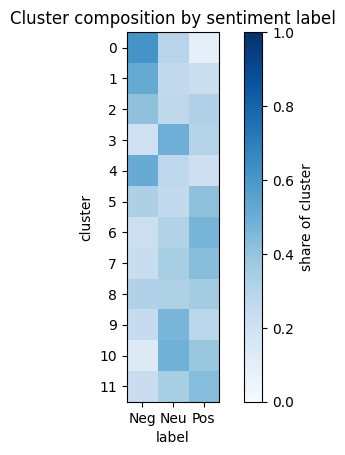

In [21]:
import matplotlib.pyplot as plt
import pandas as pd

np.random.seed(42)
k_chosen = 12  

weights, means, variances = fit_gmm(full_sentiment_train_X, k_chosen, 150, 1e-4)
resp, _ = e_step(full_sentiment_train_X, weights, means, variances)
clusters = resp.argmax(axis=1)

centered = full_sentiment_train_X - full_sentiment_train_X.mean(axis=0)
_, _, vt = np.linalg.svd(centered, full_matrices=False)
coords = centered @ vt[:2].T
plt.scatter(coords[:, 0], coords[:, 1], c=clusters, s=3, cmap="tab10")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title(f"GMM clusters (k={k_chosen}), PCA projection")
plt.show()

ct = pd.crosstab(clusters, full_sentiment_train_Y)
share = ct.div(ct.sum(axis=1), axis=0)
plt.imshow(share.values, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="share of cluster")
plt.xticks(range(3), ["Neg", "Neu", "Pos"])
plt.yticks(range(k_chosen), share.index)
plt.xlabel("label"); plt.ylabel("cluster")
plt.title("Cluster composition by sentiment label")
plt.show()

k=2  ll=19211648.25  BIC=-38403479.63
k=3  ll=19633307.02  BIC=-39236883.77
k=4  ll=19722545.02  BIC=-39405446.38
k=5  ll=20026687.04  BIC=-40003817.02
k=6  ll=20425945.04  BIC=-40792419.65
k=7  ll=20486938.92  BIC=-40904494.00
k=8  ll=20507356.20  BIC=-40935415.18
k=9  ll=20812325.14  BIC=-41535439.66
k=10  ll=20745343.12  BIC=-41391562.23
k=11  ll=20956515.60  BIC=-41803993.80
k=12  ll=21147483.21  BIC=-42176015.62
k=13  ll=20986328.17  BIC=-41843792.16


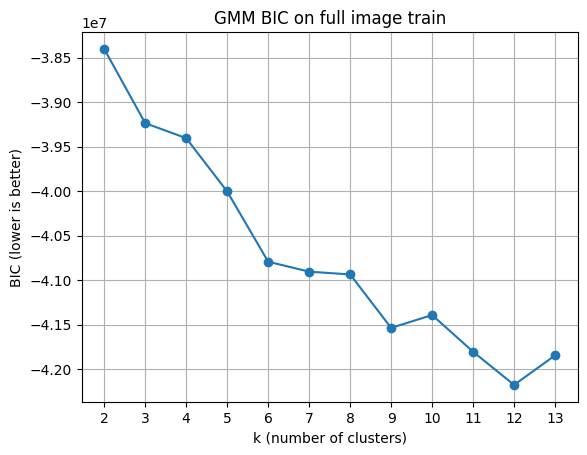

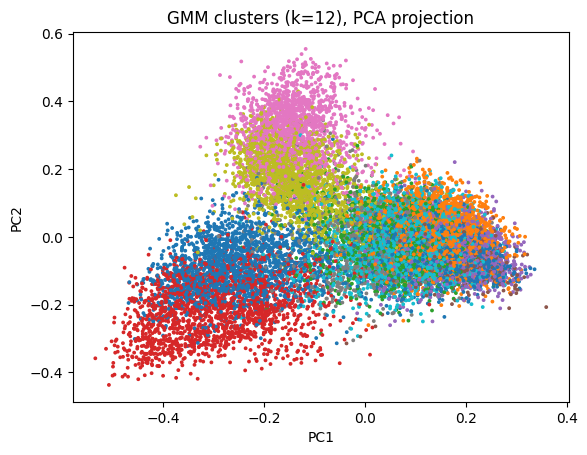

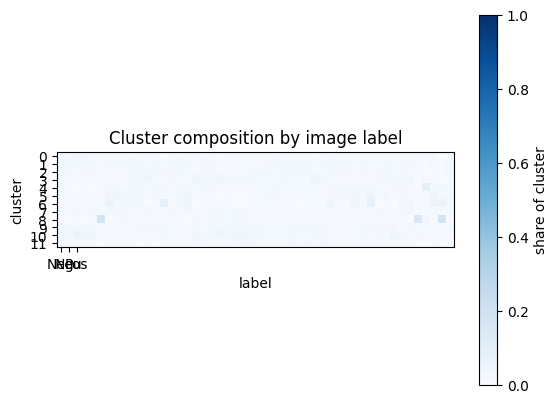

In [23]:
np.random.seed(42)

def bic_for_k(inputs, k, max_iter=150, tol=1e-4):
    weights, means, variances = fit_gmm(inputs, k, max_iter, tol)
    _, row_log_sum = e_step(inputs, weights, means, variances)
    ll = log_likelihood(row_log_sum)  
    n, d = inputs.shape
    p = (k - 1) + 2 * k * d 
    bic = p * np.log(n) - 2 * ll
    return ll, bic

bic_results = {}
for k in range(2, 14):
    ll, bic = bic_for_k(full_image_train_X, k)
    bic_results[k] = (ll, bic)
    print(f"k={k}  ll={ll:.2f}  BIC={bic:.2f}")

    import matplotlib.pyplot as plt

ks = sorted(bic_results)
bics = [bic_results[k][1] for k in ks]
plt.plot(ks, bics, marker="o")
plt.xlabel("k (number of clusters)")
plt.ylabel("BIC (lower is better)")
plt.title("GMM BIC on full image train")
plt.xticks(ks)
plt.grid(True)
plt.show()


import matplotlib.pyplot as plt
import pandas as pd

np.random.seed(42)
k_chosen = 12  

weights, means, variances = fit_gmm(full_image_train_X, k_chosen, 150, 1e-4)
resp, _ = e_step(full_image_train_X, weights, means, variances)
clusters = resp.argmax(axis=1)

centered = full_image_train_X - full_image_train_X.mean(axis=0)
_, _, vt = np.linalg.svd(centered, full_matrices=False)
coords = centered @ vt[:2].T
plt.scatter(coords[:, 0], coords[:, 1], c=clusters, s=3, cmap="vmax")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title(f"GMM clusters (k={k_chosen}), PCA projection")
plt.show()

ct = pd.crosstab(clusters, full_image_train_Y)
share = ct.div(ct.sum(axis=1), axis=0)
plt.imshow(share.values, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="share of cluster")
plt.xticks(range(3), ["Neg", "Neu", "Pos"])
plt.yticks(range(k_chosen), share.index)
plt.xlabel("label"); plt.ylabel("cluster")
plt.title("Cluster composition by image label")
plt.show()